In [1]:
## Open pickle files 

In [21]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [22]:
#pip install -e .

In [23]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [24]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [25]:
import pickle 

In [26]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)

In [27]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupted_hospitals.pkl', 'rb') as file:
    disrupted_hospitals = pickle.load(file) 

In [28]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupted_schools.pkl', 'rb') as file:
    disrupted_schools = pickle.load(file)

In [29]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_disrupted.pkl', 'rb') as file:
    rd2_disrupted = pickle.load(file)

In [30]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [31]:
import os

# Output directory
output_dir = "/cluster/home/gespejo/MOZ_struc_plots_kenneth/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
### HOSPITALS disrupted

In [32]:
def plot_disruption_map_with_hospital_levels_only_nolatlong(
    disrupted_hospitals, gadm_MOZ, output_dir
):
    import os
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import geopandas as gpd
    import numpy as np
    from shapely.geometry import Point

    os.makedirs(output_dir, exist_ok=True)

    # shape by hospital level
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {1: {'s': 24}, 2: {'s': 24}, 3: {'s': 24}, 4: {'s': 24}}  # tweak size if you like

    # colormap = truncated viridis; range 5..51 (same as roads)
    def truncate_cmap(cmap_name='viridis', minval=0.2, maxval=1.0, n=256):
        base = mpl.colormaps[cmap_name]
        new_colors = base(np.linspace(minval, maxval, n))
        return mpl.colors.ListedColormap(new_colors)

    cmap = truncate_cmap('viridis', 0.2, 1.0)
    norm = mpl.colors.Normalize(vmin=5, vmax=51)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    for hosp_key in disrupted_hospitals.keys():
        if not hosp_key.startswith("imph2_MOZ_new_Kenneth_"):
            continue

        try:
            time_id = hosp_key.split("_")[-1]
            df = disrupted_hospitals[hosp_key].copy()

            # to GeoDataFrame
            df['geometry'] = [Point(lon, lat) for lat, lon in zip(df['latitude'], df['longitude'])]
            gdf_hosp = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
            gdf_hosp['levels'] = gdf_hosp['levels'].astype(int)

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)

            # --- filled markers colored by ensemble, NO outline ---
            for level in sorted(gdf_hosp['levels'].dropna().unique()):
                if level not in level_markers:
                    continue
                sub = gdf_hosp[gdf_hosp['levels'] == level]
                vals = sub['n_ensemble_members'].to_numpy()
                fill_cols = cmap(norm(vals))                     # colors by ensemble
                ax.scatter(
                    sub.geometry.x, sub.geometry.y,
                    marker=level_markers[level],
                    s=level_style[level]['s'],
                    facecolors=fill_cols,                        # FILLED by ensemble color
                    edgecolors='none',                           # <-- no contour
                    alpha=0.95,
                    zorder=5
                )

            # extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)
            ax.set_aspect('equal', adjustable='box')
            ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel('')

            # (optional) on-map colorbar – comment out if you prefer separate legend file
            # sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
            # cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02, orientation='horizontal')
            # cbar.set_label('Disrupted Ensemble Members (Hospitals)')

            plt.tight_layout()
            fname = os.path.join(
                output_dir, f'disruption_hospitals_{time_id}_hospitals_only_ensemble.png'
            )
            plt.savefig(fname, dpi=2000)
            #plt.close(fig)

        except Exception as e:
            print(f"Error processing {hosp_key}: {e}")

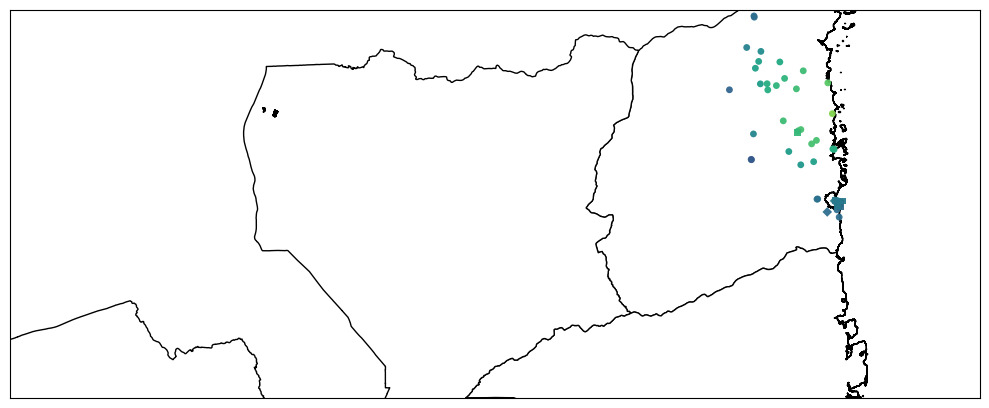

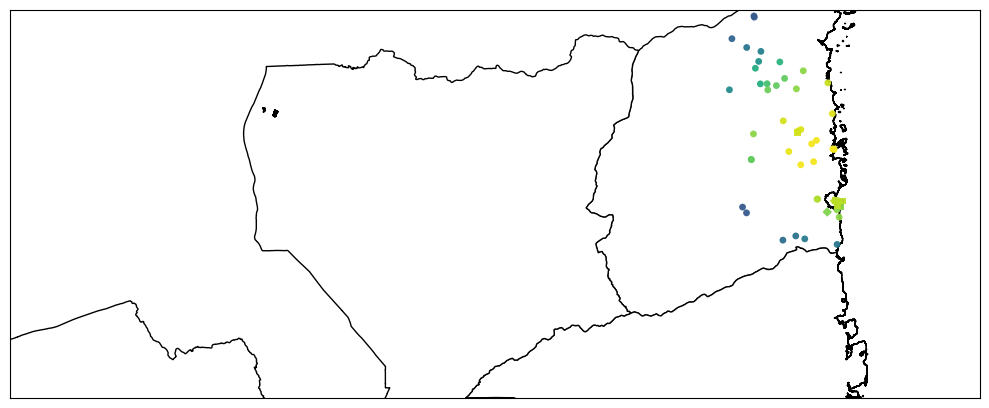

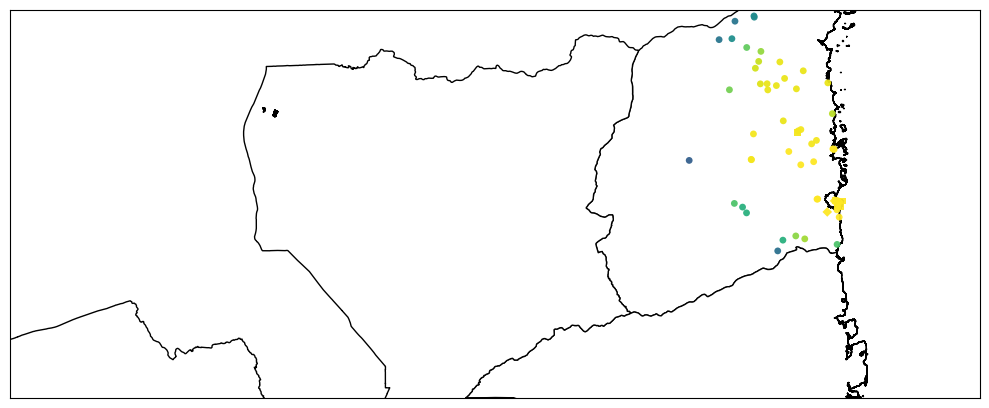

In [33]:
plot_disruption_map_with_hospital_levels_only_nolatlong(disrupted_hospitals, gadm_MOZ, output_dir)

In [31]:
### schools 

In [35]:
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import geopandas as gpd
from shapely.geometry import Point

def plot_disruption_schools_only_nolatlong(disrupted_schools, gadm_MOZ, output_dir):
    """
    Plots schools as filled markers whose color encodes n_ensemble_members.
    - Colormap: truncated 'viridis' (0.2..1.0), normalized to 5..51 (to match your roads legend).
    - No axis ticks/labels; map cropped to Mozambique extent you used.
    - No outlines around points (edgecolors='none').
    """
    os.makedirs(output_dir, exist_ok=True)
    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    # --- colormap setup (same as roads legend) ---
    def truncate_cmap(cmap_name='viridis', minval=0.2, maxval=1.0, n=256):
        base = mpl.colormaps[cmap_name]
        new_colors = base(np.linspace(minval, maxval, n))
        return mpl.colors.ListedColormap(new_colors)

    cmap = truncate_cmap('viridis', 0.2, 1.0)
    norm = mpl.colors.Normalize(vmin=5, vmax=51)   # adjust if your range differs

    for key in disrupted_schools.keys():
        # keep only your FREDDY keys; adapt the prefix if needed
        if not key.startswith("ed2_MOZ_new_Kenneth_"):
            continue

        try:
            time_id = key.split("_")[-1]
            df = disrupted_schools[key].copy()

            # ensure geometry exists; if not, try to build from lon/lat
            if 'geometry' not in df.columns:
                if {'longitude', 'latitude'}.issubset(df.columns):
                    df['geometry'] = [Point(lon, lat) for lon, lat in zip(df['longitude'], df['latitude'])]
                else:
                    print(f"Missing geometry and lon/lat in {key} — skipping.")
                    continue

            gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")

            # must have n_ensemble_members
            if 'n_ensemble_members' not in gdf.columns:
                print(f"Missing 'n_ensemble_members' in {key} — skipping.")
                continue

            vals = gdf['n_ensemble_members'].to_numpy()
            colors = cmap(norm(vals))

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)

            # plot filled points colored by ensemble; NO outline
            gdf.plot(
                ax=ax,
                color=colors,
                edgecolor='none',
                markersize=18,   # tweak size as you prefer (e.g., 14–26)
                alpha=0.95,
                zorder=3
            )

            # map extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)
            ax.set_aspect('equal', adjustable='box')
            ax.set_title('')
            ax.set_xlabel(''); ax.set_ylabel('')
            ax.set_xticks([]); ax.set_yticks([])
            ax.grid(False)

            plt.tight_layout()
            out_png = os.path.join(output_dir, f'disruption_schools_{time_id}_schools_only_ensemble.png')
            plt.savefig(out_png, dpi=2000)
            #plt.close(fig)

        except Exception as e:
            print(f"Error processing {key}: {e}")

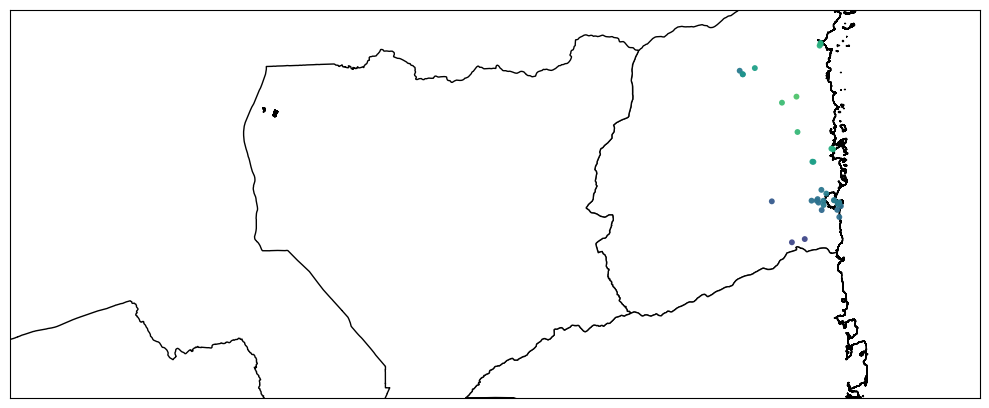

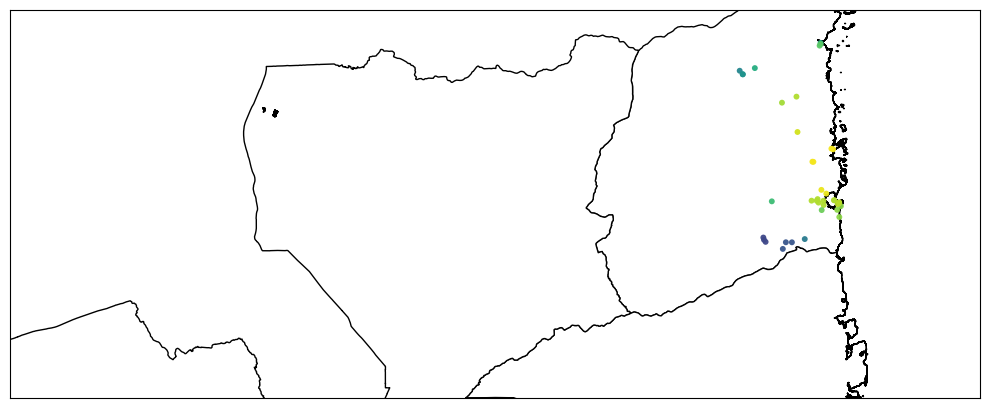

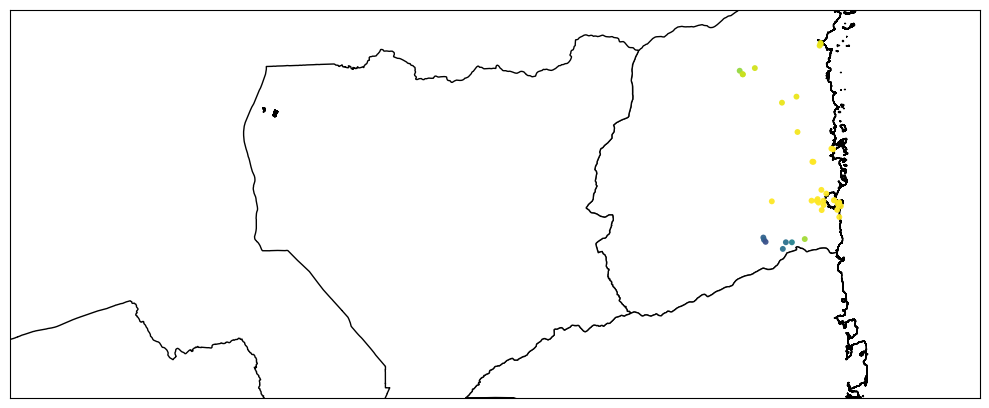

In [36]:
plot_disruption_schools_only_nolatlong(disrupted_schools, gadm_MOZ, output_dir)

In [ ]:
### Road 

In [52]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_purple = ListedColormap(plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6)))
    cmap_green = ListedColormap(plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6)))
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)

    for key in rd2_disrupted:
        impp1_key = f"impp1_MOZ_Kenneth_{key}" 
        if impp1_key not in impp1_direct or impp1_key not in impp1_disrupted:
            print(f"Skipping {key} due to missing impp1 data.")
            continue

        try:
            gdf_base = impp1_direct[impp1_key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[impp1_key].to_crs("EPSG:4326")
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: 'geometry_orig' or 'n_ensemble_members' not found.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]

            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            roads_df = gpd.sjoin(roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects').drop(columns='index_right')

            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            vmax_base = gdf_base['people'].max() if not gdf_base.empty else 1
            vmax_overlay = gdf_overlay['people'].max() if not gdf_overlay.empty else 1

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)
            norm_road = mcolors.Normalize(vmin=5, vmax=51)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            dt_obj = datetime.strptime(key, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)
            roads_df.plot(ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=3)

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.02, shrink=0.6)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.08, shrink=0.6)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            sm_road = plt.cm.ScalarMappable(cmap=cmap_road, norm=norm_road)
            sm_road.set_array([])
            cb3 = plt.colorbar(sm_road, ax=ax, orientation='vertical', pad=0.01, shrink=0.5)
            cb3.set_label('Disrupted Ensemble Members (Roads)')

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}.png')
            plt.savefig(filename, dpi=300)
            plt.close()

        except Exception as e:
            print(f"Error processing {key}: {e}")

In [48]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption_only(rd2_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)
    norm_road = mcolors.Normalize(vmin=5, vmax=51)

    for key in rd2_disrupted:
        try:
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: 'geometry_orig' or 'n_ensemble_members' not found.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]

            # Clip to Mozambique
            roads_df = gpd.sjoin(roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects').drop(columns='index_right')

            # Plotting
            dt_obj = datetime.strptime(key, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            roads_df.plot(ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=3)

            sm_road = plt.cm.ScalarMappable(cmap=cmap_road, norm=norm_road)
            sm_road.set_array([])
            #cb3 = plt.colorbar(sm_road, ax=ax, orientation='vertical', pad=0.01, shrink=0.5)
            #cb3.set_label('Disrupted Ensemble Members (Roads)', fontsize=14)
            #cb3.ax.tick_params(labelsize=12)

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude", fontsize=25)
            ax.set_ylabel("Latitude", fontsize=25)
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)
            ax.tick_params(axis='both', labelsize=25)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}_only.png')
            plt.savefig(filename, dpi=300)
            plt.close()
            print(f" Saved: {filename}")

        except Exception as e:
            print(f" Error processing {key}: {e}")

In [32]:
import os
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
from matplotlib.colors import Normalize, ListedColormap
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption_only_notlatlong(rd2_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)
    norm_road = Normalize(vmin=5, vmax=51)  # (optional; not used if no colorbar)

    for key in rd2_disrupted:
        try:
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: missing columns.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]
            roads_df = gpd.sjoin(
                roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects'
            ).drop(columns='index_right')

            # --- plot ---
            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            roads_df.plot(
                ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=2
            )

            # extent & clean axes
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)
            ax.set_aspect('equal', adjustable='box')

            # remove title, labels, and ticks
            ax.set_title('')
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}_roads_only.png')
            plt.savefig(filename, dpi=2000)
            plt.close()

        except Exception as e:
            print(f"Error processing {key}: {e}")

In [ ]:
plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, "/cluster/home/gespejo/MOZ_struc_plots_Kenneth/")

In [33]:
plot_road_disruption_only_notlatlong (rd2_disrupted, gadm_MOZ, "/cluster/home/gespejo/MOZ_struc_plots_kenneth/")

In [ ]:
### Legends 

In [143]:
import os
import matplotlib.pyplot as plt

def plot_only_hospital_legend(output_path):
    import geopandas as gpd

    # Define markers and styles
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {
        1: {'alpha': 0.8, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 100},
        2: {'alpha': 0.8, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 100},
        3: {'alpha': 0.8, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 100},
        4: {'alpha': 0.8, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 100},
    }

    # Create dummy points for legend
    fig, ax = plt.subplots(figsize=(6, 4))

    handles = []
    labels = []
    for level in sorted(level_markers.keys()):
        style = level_style[level]
        h = ax.scatter([], [], marker=level_markers[level], 
                       edgecolor=style['edgecolor'], facecolor=style['facecolor'],
                       alpha=style['alpha'], s=style['s'])
        handles.append(h)
        labels.append(f'Health Facility Level {level}')

    # Plot only the legend
    ax.legend(handles, labels, title="Hospital Levels", loc='center', fontsize=11, title_fontsize=12)
    ax.axis('off')

    # Save
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

# Example usage
plot_only_hospital_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/hospital_levels_legend_only.png")

In [145]:
import os
import matplotlib.pyplot as plt

def plot_only_school_legend(output_path):
    # Create dummy point for legend
    fig, ax = plt.subplots(figsize=(4, 3))

    # Create dummy handle for blue school dot
    handle = ax.scatter([], [], color='blue', edgecolor='blue', s=100, alpha=0.8)
    ax.legend([handle], ["Disrupted Schools"], loc='center', fontsize=11, title_fontsize=12)

    ax.axis('off')

    # Save the figure
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

# Example usage
plot_only_school_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/schools_legend_only.png")